In [2]:
import seaborn as sns

In [ ]:
df = sns.load_dataset('tips')

<Axes: xlabel='smoker'>

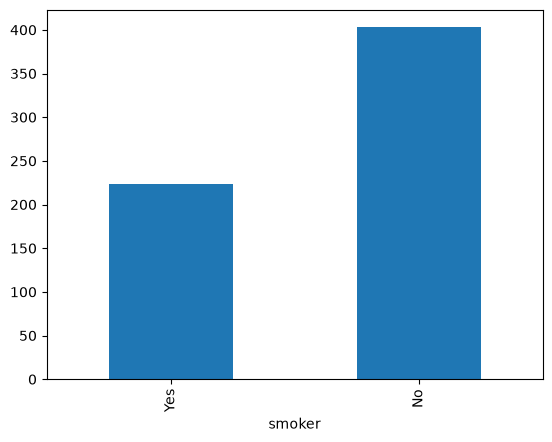

In [5]:
df.groupby('smoker')['size'].sum().plot.bar()

<Axes: xlabel='smoker', ylabel='count'>

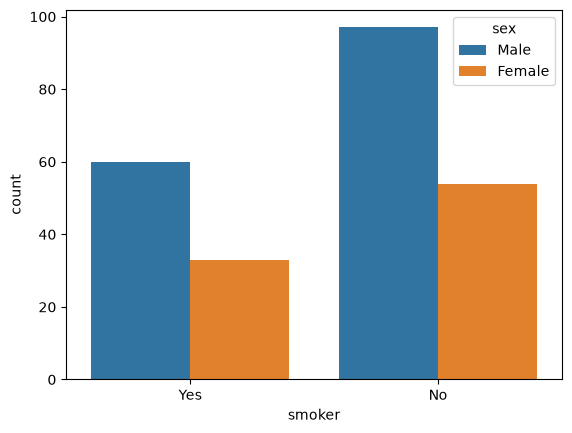

In [10]:
sns.countplot(data=df, x='smoker', hue='sex')

<Axes: xlabel='tip', ylabel='total_bill'>

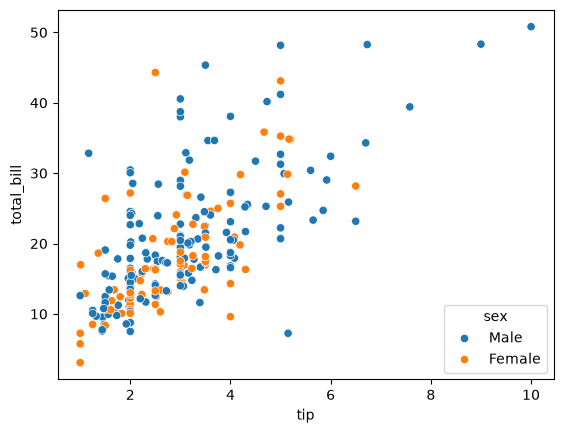

In [ ]:
sns.scatterplot(data=df, x='tip', y='total_bill', hue='sex')

<Axes: xlabel='total_bill', ylabel='Count'>

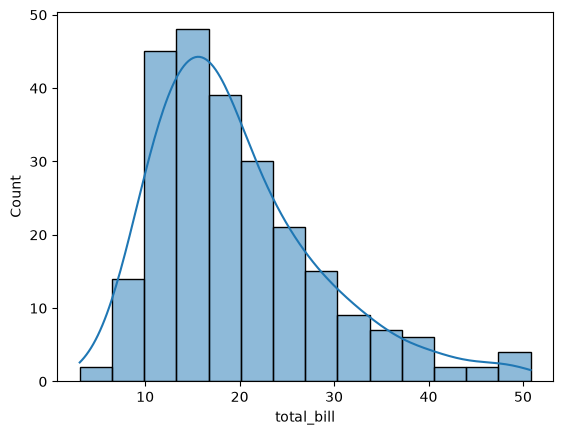

In [15]:
#melihat skewness dari data -> melihat distribusinya
sns.histplot(data=df, x='total_bill', kde=True)

<Axes: xlabel='tip', ylabel='total_bill'>

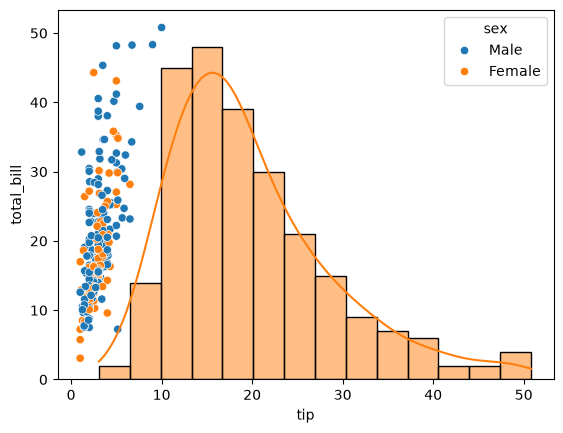

In [42]:
sns.scatterplot(data=df, x='tip', y='total_bill', hue='sex')
sns.histplot(data=df, x='total_bill', kde=True)

In [16]:
import matplotlib.pyplot as plt

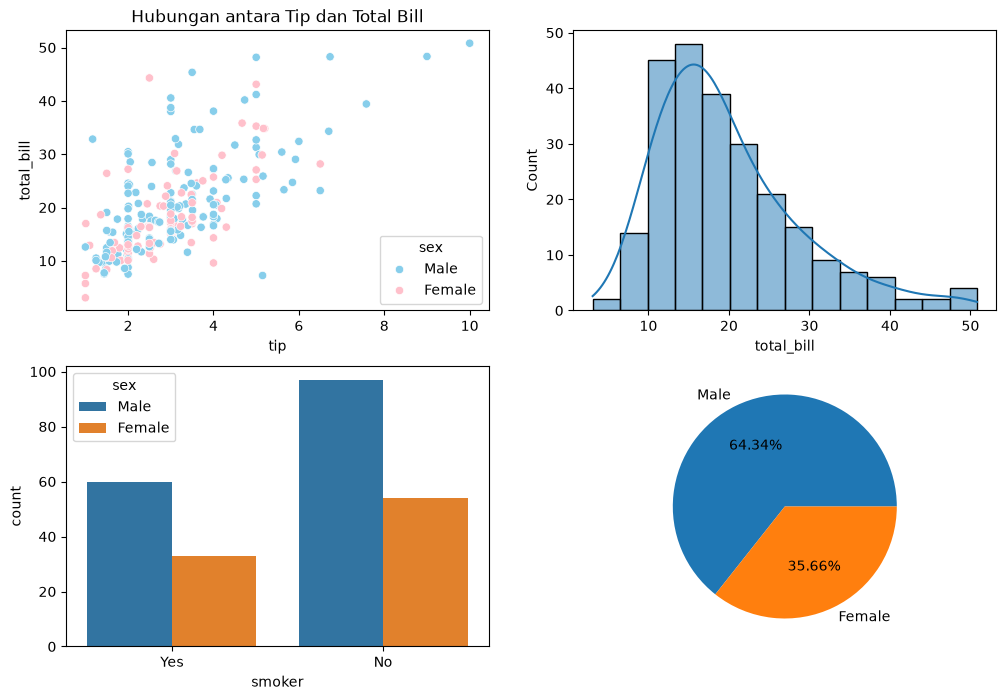

In [59]:
fig, ax = plt.subplots(2,2, figsize=(12,8))

ax = ax.flatten()

# sns.scatterplot(data=df, x='tip', y='total_bill', hue='sex', ax=ax[0], palette=sns.husl_palette(2))
sns.scatterplot(data=df, x='tip', y='total_bill', hue='sex', ax=ax[0], palette=['skyblue', 'pink'])
sns.histplot(data=df, x='total_bill', kde=True, ax = ax[1])
sns.countplot(data=df, x='smoker', hue='sex', ax = ax[2])

ax[3].pie(df['sex'].value_counts(), labels=df['sex'].value_counts().index, autopct='%.2f%%')

ax[0].set_title('Hubungan antara Tip dan Total Bill')

plt.savefig('chart.png')

In [26]:
ax[0,0]

<Axes: >

In [27]:
import numpy as np

In [36]:
arr2 = np.array([[1,2,3,4,5],[6,7,8,9,10]])
#mmerubah n dimensional array -> 1 dimensional array: flatten, ravel
# flatten -> membuat salinan baru dari array
# ravel -> membuat view dari array, mengubah nialai dari array aslinya

r = arr2.ravel()
r[0] = 100

f = arr2.flatten()
f[0] = 90
arr2

array([[100,   2,   3,   4,   5],
       [  6,   7,   8,   9,  10]])

In [29]:
arr2[1,2]

np.int64(8)

In [46]:
sns.dark_palette('green')
sns.husl_palette()

[(0.9677975592919913, 0.44127456009157356, 0.5358103155058701),
 (0.7350228985632719, 0.5952719904750953, 0.1944419133847522),
 (0.3126890019504329, 0.6928754610296064, 0.1923704830330379),
 (0.21044753832183283, 0.6773105080456748, 0.6433941168468681),
 (0.23299120924703914, 0.639586552066035, 0.9260706093977744),
 (0.9082572436765556, 0.40195790729656516, 0.9576909250290225)]

In [53]:
df['sex'].value_counts().index

CategoricalIndex(['Male', 'Female'], categories=['Male', 'Female'], ordered=False, dtype='category', name='sex')

## Handling Missing Value
1. Menghapus data: kalau butuh effort lebih, jumlahnya tidak terlalu banyak
2. Imputasi: mean, median, modus, interpolate (khusus untuk data yang punya pola)

In [71]:
df = sns.load_dataset('titanic')
df.isnull().sum()
df.drop(columns='deck', inplace=True)

In [67]:
import pandas as pd

In [68]:
pd.isnull(df['age'].values[0])

False

In [72]:
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,Cherbourg,yes,True


In [73]:
df[df['embark_town'].isnull()]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
61,1,1,female,38.0,0,0,80.0,NaN,First,woman,False,NaN,yes,True
829,1,1,female,62.0,0,0,80.0,NaN,First,woman,False,NaN,yes,True


In [77]:
df.groupby(['class', 'embark_town'])['fare'].median()

class   embark_town
First   Cherbourg      78.2667
        Queenstown     90.0000
        Southampton    52.0000
Second  Cherbourg      24.0000
        Queenstown     12.3500
        Southampton    13.5000
Third   Cherbourg       7.8958
        Queenstown      7.7500
        Southampton     8.0500
Name: fare, dtype: float64

In [95]:
df['embark_town'] = df['embark_town'].fillna('Cherbourg', inplace=True)

C:\Users\arifw\AppData\Local\Temp\ipykernel_2140\1672254165.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['embark_town'] = df['embark_town'].fillna('Cherbourg', inplace=True)


In [96]:
df['embarked'] = df['embarked'].fillna('C', inplace=True)

C:\Users\arifw\AppData\Local\Temp\ipykernel_2140\137693472.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['embarked'] = df['embarked'].fillna('C', inplace=True)


In [97]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         0
class            0
who              0
adult_male       0
embark_town      0
alive            0
alone            0
dtype: int64

In [90]:
df[df['age'].isnull()]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,Queenstown,no,True
17,1,2,male,NaN,0,0,13.0000,S,Second,man,True,Southampton,yes,True
19,1,3,female,NaN,0,0,7.2250,C,Third,woman,False,Cherbourg,yes,True
26,0,3,male,NaN,0,0,7.2250,C,Third,man,True,Cherbourg,no,True
28,1,3,female,NaN,0,0,7.8792,Q,Third,woman,False,Queenstown,yes,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
859,0,3,male,NaN,0,0,7.2292,C,Third,man,True,Cherbourg,no,True
863,0,3,female,NaN,8,2,69.5500,S,Third,woman,False,Southampton,no,False
868,0,3,male,NaN,0,0,9.5000,S,Third,man,True,Southampton,no,True
878,0,3,male,NaN,0,0,7.8958,S,Third,man,True,Southampton,no,True


In [92]:
df['who'].unique()
df.groupby(['who'])['age'].mean()

who
child     6.369518
man      33.173123
woman    32.000000
Name: age, dtype: float64

In [93]:
df[df['age'].isnull()]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,Queenstown,no,True
17,1,2,male,NaN,0,0,13.0000,S,Second,man,True,Southampton,yes,True
19,1,3,female,NaN,0,0,7.2250,C,Third,woman,False,Cherbourg,yes,True
26,0,3,male,NaN,0,0,7.2250,C,Third,man,True,Cherbourg,no,True
28,1,3,female,NaN,0,0,7.8792,Q,Third,woman,False,Queenstown,yes,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
859,0,3,male,NaN,0,0,7.2292,C,Third,man,True,Cherbourg,no,True
863,0,3,female,NaN,8,2,69.5500,S,Third,woman,False,Southampton,no,False
868,0,3,male,NaN,0,0,9.5000,S,Third,man,True,Southampton,no,True
878,0,3,male,NaN,0,0,7.8958,S,Third,man,True,Southampton,no,True


In [98]:
df[df['sex'] == 'male']

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,Southampton,no,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
883,0,2,male,28.0,0,0,10.5000,S,Second,man,True,Southampton,no,True
884,0,3,male,25.0,0,0,7.0500,S,Third,man,True,Southampton,no,True
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,Southampton,no,True
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,Cherbourg,yes,True


In [100]:
df['age'] = df.apply(lambda x: 33 if (x['who'] == 'man') & (pd.isnull(x['age'])) else 32 if (x['who'] == 'woman') & (pd.isnull(x['age'])) else x['age'], axis=1)

In [102]:
df.isnull().sum()

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

In [107]:
data = pd.DataFrame([[1,100], [2,120], [3, np.nan], [4,160]], columns=['No', 'Nilai'])

In [108]:
data

,No,Nilai
0,1,100.0
1,2,120.0
2,3,NaN
3,4,160.0


In [110]:
import pandas as pd
import numpy as np
data = pd.DataFrame([[1, 100], [2, 120], [3, np.nan], [4, 160]], columns=['No', 'Nilai'])
data['Nilai'] = data['Nilai'].interpolate()
data

,No,Nilai
0,1,100.0
1,2,120.0
2,3,140.0
3,4,160.0


# Unsurpervised Learning
## Clustering

case: segmentasi customer berdasarkan data finansial dan demografis

1. K-Means      -> menggunakan centroid
2. Mean-Shift   -> density
3. DBSCAN       -> density

In [121]:
pd.read_csv('life_insurance.csv')
df = pd.read_csv(r'C:\Users\arifw\Documents\Personal Documents\Jasaraharja Putera\IT General\Pelatihan\Machine Learning\life_insurance.csv')

In [122]:
df.isnull().sum()

customer_id             0
name                    0
age                     0
gender                  0
marital_status          0
number_of_dependents    0
annual_income           0
occupation              0
health_status           0
smoking_status          0
policy_type             0
coverage_amount         0
monthly_premium         0
policy_start_date       0
dtype: int64

# Feature Engineering

### Feature Selection

1. Filter Method -> menggunakan statistik deskriptif
2. Wrapper Method -> uji kombinasi feature
3. embedded Method -> feature selection dijalankan dalam model (L1/L2)

In [123]:
df

,customer_id,name,age,gender,marital_status,number_of_dependents,annual_income,occupation,health_status,smoking_status,policy_type,coverage_amount,monthly_premium,policy_start_date
0,mostly88-ab02-43a7-8fe5-5121b6085a62,Hia Thonpson,53,Female,Married,3,120000,Elemtrical Engineer,Excellent,Former smoker,Universal Life,700000,325.9,2022-07-01
1,mostlyd9-807b-4b55-ba15-e605f31d46ad,Jame Bolwio,26,Female,Married,1,54000,Graphic Designer,Good,Former smoker,Whole Life,100000,67.4,2022-05-19
2,mostly90-b192-4052-8b43-79a3b9052900,Chloe ore,47,Female,Single,0,52000,School iecipal,Good,Non-smoker,Term Life,250000,60.7,2022-08-11
3,mostly63-89d3-4c9b-bfa6-a83134d3eaa6,Camoe Wilson,47,Male,Single,0,62000,Content teatorist,Good,Current smoker,Term Life,150000,38.1,2022-11-03
4,mostly31-5880-4d5a-99e3-29254d2d9ea9,Avde Waln,52,Female,Married,3,155000,Scleor srector,Excellent,Non-smoker,Whole Life,900000,126.3,2022-10-20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,mostly28-207e-4e24-b805-b1683de6bc41,Nanhel Ritrs,28,Male,Single,0,62000,Marketing Moordinator,Excellent,Non-smoker,Term Life,200000,52.7,2022-05-18
9996,mostly21-e5fe-499f-82f2-c0b517504df0,Liam Gatel,33,Male,Married,1,68000,Operations Manager,Good,Non-smoker,Term Life,260000,96.1,2022-07-22
9997,mostly9f-adbf-406d-a7ce-f24969fed9d8,Avde hnnr,26,Female,Married,2,93000,Retired,Fair,Non-smoker,Whole Life,500000,78.1,2022-09-30
9998,mostly13-4bc5-44c4-91a1-994536c7802d,Ava arsis,65,Female,Married,2,88000,Reaired,Fair,Non-smoker,Term Life,100000,38.1,2022-12-02


In [130]:
# segmentasi customer
df.columns
feature = ['age', 'gender', 'marital_status', 'number_of_dependents', 'annual_income', 'occupation', 'health_status', 'smoking_status', 'policy_type', 'coverage_amount', 'monthly_premium', 'policy_start_date']

In [131]:
X = df[feature]

np.float64(1.0985288448816124)

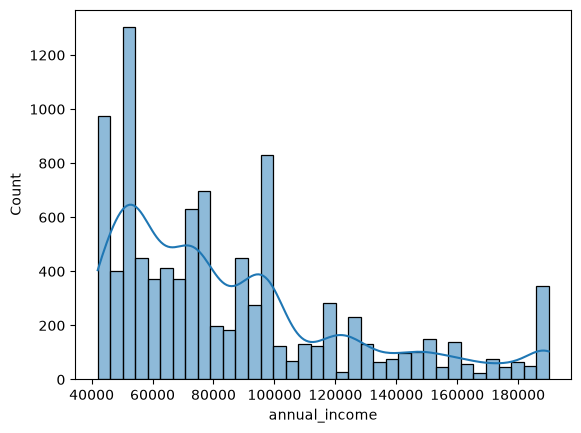

In [ ]:
sns.histplot(data=X, x=X['annual_income'], kde=True)
X['annual_income'].skew()
#skewness normal: < 0.5, sedang: < 1, sangat skew: > 1

### Feature Transformation
1. Log Transformation np.log
2. Cari akar kuadrat .sqrt
3. Binning : merubah numerik ke kategori

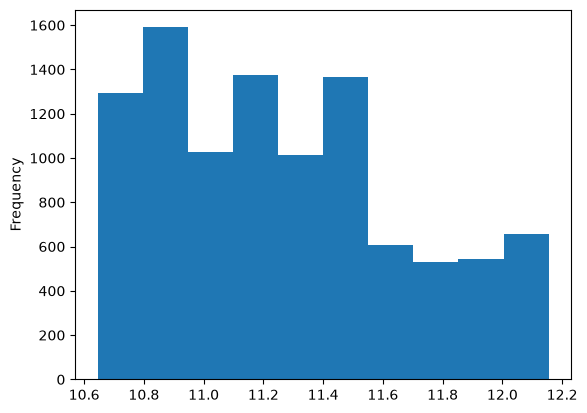

In [149]:
np.log1p(X['annual_income']).skew()
np.log1p(X['annual_income']).plot.hist()
X['annual_income'] = np.log1p(X['annual_income'])

<Axes: xlabel='annual_income', ylabel='Count'>

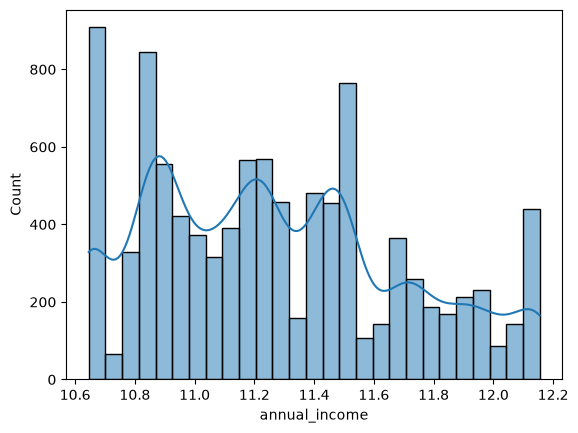

In [143]:
sns.histplot(data=X, x=np.log1p(X['annual_income']), kde=True)

In [138]:
X['annual_income']

0       120000
1        54000
2        52000
3        62000
4       155000
         ...  
9995     62000
9996     68000
9997     93000
9998     88000
9999     98000
Name: annual_income, Length: 10000, dtype: int64

In [142]:
np.sqrt(X['annual_income'])

0       346.410162
1       232.379001
2       228.035085
3       248.997992
4       393.700394
           ...    
9995    248.997992
9996    260.768096
9997    304.959014
9998    296.647939
9999    313.049517
Name: annual_income, Length: 10000, dtype: float64

In [148]:
bins = [0, 100000, 150000, 200000]
label = ['rendah', 'sedang', 'tinggi']

pd.cut(X['annual_income'], bins=bins, labels=label)

0       sedang
1       rendah
2       rendah
3       rendah
4       tinggi
         ...  
9995    rendah
9996    rendah
9997    rendah
9998    rendah
9999    rendah
Name: annual_income, Length: 10000, dtype: category
Categories (3, str): ['rendah' < 'sedang' < 'tinggi']

In [150]:
s=X['annual_income']
print(s.min(), s.skew(), np.log1p(s).skew(), np.sqrt(s).skew())

10.645448706505872 0.38908512816420093 0.3332857211070973 0.35867990517451853


In [151]:
X

,age,gender,marital_status,number_of_dependents,annual_income,occupation,health_status,smoking_status,policy_type,coverage_amount,monthly_premium,policy_start_date
0,53,Female,Married,3,11.695255,Elemtrical Engineer,Excellent,Former smoker,Universal Life,700000,325.9,2022-07-01
1,26,Female,Married,1,10.896758,Graphic Designer,Good,Former smoker,Whole Life,100000,67.4,2022-05-19
2,47,Female,Single,0,10.859018,School iecipal,Good,Non-smoker,Term Life,250000,60.7,2022-08-11
3,47,Male,Single,0,11.034906,Content teatorist,Good,Current smoker,Term Life,150000,38.1,2022-11-03
4,52,Female,Married,3,11.951187,Scleor srector,Excellent,Non-smoker,Whole Life,900000,126.3,2022-10-20
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,28,Male,Single,0,11.034906,Marketing Moordinator,Excellent,Non-smoker,Term Life,200000,52.7,2022-05-18
9996,33,Male,Married,1,11.127278,Operations Manager,Good,Non-smoker,Term Life,260000,96.1,2022-07-22
9997,26,Female,Married,2,11.440366,Retired,Fair,Non-smoker,Whole Life,500000,78.1,2022-09-30
9998,65,Female,Married,2,11.385103,Reaired,Fair,Non-smoker,Term Life,100000,38.1,2022-12-02


In [ ]:
X['coverage_amount'].skew()

np.float64(1.1060882786480941)

In [153]:
X['coverage_amount'] = np.log1p(X['coverage_amount'])

In [154]:
X

,age,gender,marital_status,number_of_dependents,annual_income,occupation,health_status,smoking_status,policy_type,coverage_amount,monthly_premium,policy_start_date
0,53,Female,Married,3,11.695255,Elemtrical Engineer,Excellent,Former smoker,Universal Life,13.458837,325.9,2022-07-01
1,26,Female,Married,1,10.896758,Graphic Designer,Good,Former smoker,Whole Life,11.512935,67.4,2022-05-19
2,47,Female,Single,0,10.859018,School iecipal,Good,Non-smoker,Term Life,12.429220,60.7,2022-08-11
3,47,Male,Single,0,11.034906,Content teatorist,Good,Current smoker,Term Life,11.918397,38.1,2022-11-03
4,52,Female,Married,3,11.951187,Scleor srector,Excellent,Non-smoker,Whole Life,13.710151,126.3,2022-10-20
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,28,Male,Single,0,11.034906,Marketing Moordinator,Excellent,Non-smoker,Term Life,12.206078,52.7,2022-05-18
9996,33,Male,Married,1,11.127278,Operations Manager,Good,Non-smoker,Term Life,12.468441,96.1,2022-07-22
9997,26,Female,Married,2,11.440366,Retired,Fair,Non-smoker,Whole Life,13.122365,78.1,2022-09-30
9998,65,Female,Married,2,11.385103,Reaired,Fair,Non-smoker,Term Life,11.512935,38.1,2022-12-02


In [155]:
X['gender'].unique()

<StringArray>
['Female', 'Male', '_RARE_']
Length: 3, dtype: str

In [159]:
X[X['gender'] == '_RARE_'].index

Index([  51,  584,  716, 1193, 1678, 1888, 2299, 2522, 2855, 3431, 3894, 4165,
       4808, 4904, 5265, 5814, 5876, 6030, 6334, 6602, 7090, 7148, 7743, 8053,
       8251, 8450, 8817, 8958, 9265, 9342, 9496, 9627, 9646, 9798],
      dtype='int64')

In [166]:
X.drop(X[X['gender'] == '_RARE_'].index, inplace=True)

In [167]:
X.reset_index(drop=True, inplace=True)

In [168]:
X

,age,gender,marital_status,number_of_dependents,annual_income,occupation,health_status,smoking_status,policy_type,coverage_amount,monthly_premium,policy_start_date
0,53,Female,Married,3,11.695255,Elemtrical Engineer,Excellent,Former smoker,Universal Life,13.458837,325.9,2022-07-01
1,26,Female,Married,1,10.896758,Graphic Designer,Good,Former smoker,Whole Life,11.512935,67.4,2022-05-19
2,47,Female,Single,0,10.859018,School iecipal,Good,Non-smoker,Term Life,12.429220,60.7,2022-08-11
3,47,Male,Single,0,11.034906,Content teatorist,Good,Current smoker,Term Life,11.918397,38.1,2022-11-03
4,52,Female,Married,3,11.951187,Scleor srector,Excellent,Non-smoker,Whole Life,13.710151,126.3,2022-10-20
...,...,...,...,...,...,...,...,...,...,...,...,...
9961,28,Male,Single,0,11.034906,Marketing Moordinator,Excellent,Non-smoker,Term Life,12.206078,52.7,2022-05-18
9962,33,Male,Married,1,11.127278,Operations Manager,Good,Non-smoker,Term Life,12.468441,96.1,2022-07-22
9963,26,Female,Married,2,11.440366,Retired,Fair,Non-smoker,Whole Life,13.122365,78.1,2022-09-30
9964,65,Female,Married,2,11.385103,Reaired,Fair,Non-smoker,Term Life,11.512935,38.1,2022-12-02


In [169]:
X['marital_status'].unique()

<StringArray>
['Married', 'Single', 'Widowed', 'Divorced']
Length: 4, dtype: str

### Encoding
1. label encoding
2. one hot encoding: data nominal
3. ordinal encoding: data ordinal

In [172]:
X['gender'] = X['gender'].map({'Female': 0, 'Male': 1})

In [173]:
X

,age,gender,marital_status,number_of_dependents,annual_income,occupation,health_status,smoking_status,policy_type,coverage_amount,monthly_premium,policy_start_date
0,53,0,Married,3,11.695255,Elemtrical Engineer,Excellent,Former smoker,Universal Life,13.458837,325.9,2022-07-01
1,26,0,Married,1,10.896758,Graphic Designer,Good,Former smoker,Whole Life,11.512935,67.4,2022-05-19
2,47,0,Single,0,10.859018,School iecipal,Good,Non-smoker,Term Life,12.429220,60.7,2022-08-11
3,47,1,Single,0,11.034906,Content teatorist,Good,Current smoker,Term Life,11.918397,38.1,2022-11-03
4,52,0,Married,3,11.951187,Scleor srector,Excellent,Non-smoker,Whole Life,13.710151,126.3,2022-10-20
...,...,...,...,...,...,...,...,...,...,...,...,...
9961,28,1,Single,0,11.034906,Marketing Moordinator,Excellent,Non-smoker,Term Life,12.206078,52.7,2022-05-18
9962,33,1,Married,1,11.127278,Operations Manager,Good,Non-smoker,Term Life,12.468441,96.1,2022-07-22
9963,26,0,Married,2,11.440366,Retired,Fair,Non-smoker,Whole Life,13.122365,78.1,2022-09-30
9964,65,0,Married,2,11.385103,Reaired,Fair,Non-smoker,Term Life,11.512935,38.1,2022-12-02


In [177]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

In [185]:
# fit, transform, predict

# instansiasi objek
oe = OrdinalEncoder(categories=[['Fair', 'Good', 'Excellent']])

In [178]:
X.head()

,age,gender,marital_status,number_of_dependents,annual_income,occupation,health_status,smoking_status,policy_type,coverage_amount,monthly_premium,policy_start_date
0,53,0,Married,3,11.695255,Elemtrical Engineer,Excellent,Former smoker,Universal Life,13.458837,325.9,2022-07-01
1,26,0,Married,1,10.896758,Graphic Designer,Good,Former smoker,Whole Life,11.512935,67.4,2022-05-19
2,47,0,Single,0,10.859018,School iecipal,Good,Non-smoker,Term Life,12.429220,60.7,2022-08-11
3,47,1,Single,0,11.034906,Content teatorist,Good,Current smoker,Term Life,11.918397,38.1,2022-11-03
4,52,0,Married,3,11.951187,Scleor srector,Excellent,Non-smoker,Whole Life,13.710151,126.3,2022-10-20


In [179]:
X.drop(X[X['health_status'] == '_RARE_'].index, inplace=True)

In [180]:
X.reset_index(drop=True, inplace=True)

In [182]:
X['health_status'].unique()

<StringArray>
['Excellent', 'Good', 'Fair']
Length: 3, dtype: str

In [188]:
X['health_status'] = oe.fit_transform(X[['health_status']])

In [187]:
oe.categories

[['Fair', 'Good', 'Excellent']]

In [191]:
X

,age,gender,marital_status,number_of_dependents,annual_income,occupation,health_status,smoking_status,policy_type,coverage_amount,monthly_premium,policy_start_date
0,53,0,Married,3,11.695255,Elemtrical Engineer,2.0,Former smoker,Universal Life,13.458837,325.9,2022-07-01
1,26,0,Married,1,10.896758,Graphic Designer,1.0,Former smoker,Whole Life,11.512935,67.4,2022-05-19
2,47,0,Single,0,10.859018,School iecipal,1.0,Non-smoker,Term Life,12.429220,60.7,2022-08-11
3,47,1,Single,0,11.034906,Content teatorist,1.0,Current smoker,Term Life,11.918397,38.1,2022-11-03
4,52,0,Married,3,11.951187,Scleor srector,2.0,Non-smoker,Whole Life,13.710151,126.3,2022-10-20
...,...,...,...,...,...,...,...,...,...,...,...,...
9925,28,1,Single,0,11.034906,Marketing Moordinator,2.0,Non-smoker,Term Life,12.206078,52.7,2022-05-18
9926,33,1,Married,1,11.127278,Operations Manager,1.0,Non-smoker,Term Life,12.468441,96.1,2022-07-22
9927,26,0,Married,2,11.440366,Retired,0.0,Non-smoker,Whole Life,13.122365,78.1,2022-09-30
9928,65,0,Married,2,11.385103,Reaired,0.0,Non-smoker,Term Life,11.512935,38.1,2022-12-02


In [ ]:
ohe = OneHotEncoder(sparse_output=False)
ohe.fit_transform(X[['marital_status']])
ohe.get_feature_names_out()

data_marital = pd.DataFrame(ohe.fit_transform(X[['marital_status']]), columns=ohe.get_feature_names_out())

X = pd.concat([X, data_marital], axis=1)

In [198]:
X.drop(columns='marital_status', inplace=True)

In [199]:
X

,age,gender,number_of_dependents,annual_income,occupation,health_status,smoking_status,policy_type,coverage_amount,monthly_premium,policy_start_date,marital_status_Divorced,marital_status_Married,marital_status_Single,marital_status_Widowed
0,53,0,3,11.695255,Elemtrical Engineer,2.0,Former smoker,Universal Life,13.458837,325.9,2022-07-01,0.0,1.0,0.0,0.0
1,26,0,1,10.896758,Graphic Designer,1.0,Former smoker,Whole Life,11.512935,67.4,2022-05-19,0.0,1.0,0.0,0.0
2,47,0,0,10.859018,School iecipal,1.0,Non-smoker,Term Life,12.429220,60.7,2022-08-11,0.0,0.0,1.0,0.0
3,47,1,0,11.034906,Content teatorist,1.0,Current smoker,Term Life,11.918397,38.1,2022-11-03,0.0,0.0,1.0,0.0
4,52,0,3,11.951187,Scleor srector,2.0,Non-smoker,Whole Life,13.710151,126.3,2022-10-20,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9925,28,1,0,11.034906,Marketing Moordinator,2.0,Non-smoker,Term Life,12.206078,52.7,2022-05-18,0.0,0.0,1.0,0.0
9926,33,1,1,11.127278,Operations Manager,1.0,Non-smoker,Term Life,12.468441,96.1,2022-07-22,0.0,1.0,0.0,0.0
9927,26,0,2,11.440366,Retired,0.0,Non-smoker,Whole Life,13.122365,78.1,2022-09-30,0.0,1.0,0.0,0.0
9928,65,0,2,11.385103,Reaired,0.0,Non-smoker,Term Life,11.512935,38.1,2022-12-02,0.0,1.0,0.0,0.0


In [202]:
X = X[['age', 'gender', 'number_of_dependents', 'annual_income', 'health_status', 'coverage_amount',
       'monthly_premium', 'policy_start_date', 'marital_status_Divorced',
       'marital_status_Married', 'marital_status_Single',
       'marital_status_Widowed']]

In [211]:
pd.to_datetime(X['policy_start_date'])

X['tenure'] = ((pd.Timestamp.today() - pd.to_datetime(X['policy_start_date'])).dt.days/365.25).round(1)

In [212]:
X.drop(columns='policy_start_date', inplace=True)

In [213]:
X

,age,gender,number_of_dependents,annual_income,health_status,coverage_amount,monthly_premium,marital_status_Divorced,marital_status_Married,marital_status_Single,marital_status_Widowed,tenure
0,53,0,3,11.695255,2.0,13.458837,325.9,0.0,1.0,0.0,0.0,4.2
1,26,0,1,10.896758,1.0,11.512935,67.4,0.0,1.0,0.0,0.0,4.4
2,47,0,0,10.859018,1.0,12.429220,60.7,0.0,0.0,1.0,0.0,4.1
3,47,1,0,11.034906,1.0,11.918397,38.1,0.0,0.0,1.0,0.0,3.9
4,52,0,3,11.951187,2.0,13.710151,126.3,0.0,1.0,0.0,0.0,3.9
...,...,...,...,...,...,...,...,...,...,...,...,...
9925,28,1,0,11.034906,2.0,12.206078,52.7,0.0,0.0,1.0,0.0,4.4
9926,33,1,1,11.127278,1.0,12.468441,96.1,0.0,1.0,0.0,0.0,4.2
9927,26,0,2,11.440366,0.0,13.122365,78.1,0.0,1.0,0.0,0.0,4.0
9928,65,0,2,11.385103,0.0,11.512935,38.1,0.0,1.0,0.0,0.0,3.8


### Scaling
1. MinMaxScaler -> 0 - 1
2. StandardScaler -> mean = 0 dan std = 1

In [215]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [216]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [217]:
X_scaled

array([[ 0.91807094, -0.91944652,  1.5790646 , ..., -0.57649752,
        -0.27091968, -0.26871046],
       [-1.40601555, -0.91944652, -0.25551028, ..., -0.57649752,
        -0.27091968,  0.43981181],
       [ 0.40160728, -0.91944652, -1.17279772, ...,  1.73461284,
        -0.27091968, -0.6229716 ],
       ...,
       [-1.40601555, -0.91944652,  0.66177716, ..., -0.57649752,
        -0.27091968, -0.97723273],
       [ 1.95099827, -0.91944652,  0.66177716, ..., -0.57649752,
        -0.27091968, -1.685755  ],
       [-1.233861  , -0.91944652,  0.66177716, ..., -0.57649752,
        -0.27091968,  0.43981181]], shape=(9930, 12))

## Build Model

### KMeans

In [218]:
from sklearn.cluster import KMeans

In [222]:
km = KMeans(n_clusters=3, n_init=10, random_state=42)

#training model
km.fit(X_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 12)","[[ 0

In [223]:
km.predict(X_scaled)

array([0, 0, 2, ..., 0, 0, 0], shape=(9930,), dtype=int32)

In [221]:
try:
    print(km)
    print('labels', np.bincount(km.labels_))
    print('inertia', km.inertia_, 'iter', km.n_iter_)
    print(pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=X.columns).round(2).T)
except Exception as e:
    print(type(e).__name__, e)

KMeans(n_clusters=3, n_init=10, random_state=42)
labels [5902 1509 2519]
inertia 77061.73214468472 iter 11
                              0       1      2
age                       43.46   48.04  36.28
gender                     0.47    0.50   0.40
number_of_dependents       1.86    1.08   0.04
annual_income             11.42   11.25  10.92
health_status              1.26    1.01   1.36
coverage_amount           12.85   12.60  11.93
monthly_premium          199.98  155.99  62.33
marital_status_Divorced    0.00    0.55   0.00
marital_status_Married     1.00    0.00   0.02
marital_status_Single      0.00   -0.00   0.98
marital_status_Widowed     0.00    0.45   0.00
tenure                     4.29    4.26   4.27


In [224]:
km.inertia_

77061.73214468472

In [229]:
# intertia = WCSS -> within cluster sum of square
intertia = []

for i in range(2,20):
    km = KMeans(n_clusters=i, n_init=10, random_state=42)
    km.fit(X_scaled)
    intertia.append(km.inertia_)

In [230]:
intertia

[90674.29598031196,
 77061.73214468473,
 66082.82843495594,
 57685.19563583758,
 54404.033627712815,
 51882.31030796634,
 49691.69339813255,
 47450.07854942825,
 46207.951294550854,
 44715.697375626085,
 43698.76874296673,
 42468.39236970584,
 41524.992877360026,
 40422.53478880385,
 39930.2906172337,
 38777.53523266566,
 38353.43264938209,
 37117.4210558542]

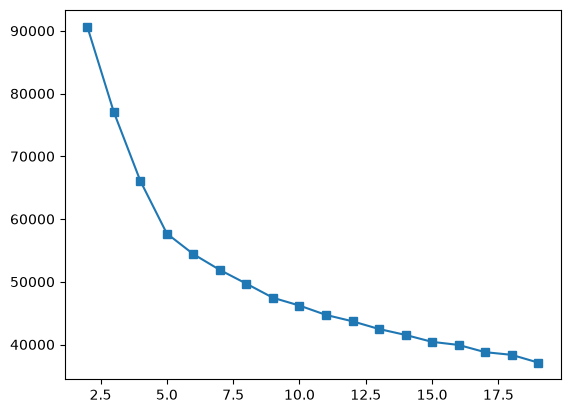

In [232]:
plt.plot(range(2,20), intertia, marker='s')

In [234]:
from sklearn.metrics import silhouette_score

sh_score = []

for i in range(2,20):
    km = KMeans(n_clusters=i, n_init=10, random_state=42)
    km.fit(X_scaled)
    cluster = km.predict(X_scaled)
    sh_score.append(silhouette_score(X_scaled, cluster))

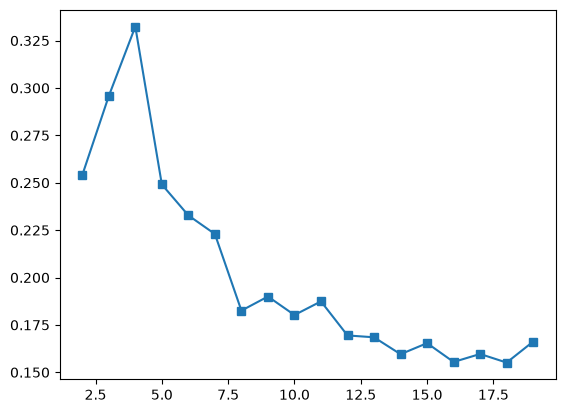

In [237]:
plt.plot(range(2,20), sh_score, marker='s')

### Evaluasi Mode
1. Silhoutte Score -> semakin mendekati 1, semakin bagus
2. Calinski Harabasz -> semakin besar, semakin bagus

In [238]:
from sklearn.metrics import calinski_harabasz_score

In [244]:
km = KMeans(n_clusters=4, n_init=10, random_state=42)

km_cluster = km.fit_predict(X_scaled)

print('Silhoutte Score: ', silhouette_score(X_scaled, km_cluster))
print('Calinski Score: ', calinski_harabasz_score(X_scaled, km_cluster))

Silhoutte Score:  0.33239130764598795
Calinski Score:  2657.4939530026213


In [245]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score
for _k in range(2,9):
    _lab = KMeans(n_clusters=_k, n_init=10, random_state=42).fit_predict(X_scaled)
    print(_k, round(silhouette_score(X_scaled,_lab),3), round(calinski_harabasz_score(X_scaled,_lab),1))

2 0.254 3118.9
3 0.296 2711.5
4 0.332 2657.5
5 0.249 2644.3
6 0.233 2362.5
7 0.223 2144.6
8 0.183 1981.6


In [246]:
X['km_cluster'] = km_cluster

In [247]:
X.groupby('km_cluster').mean()

,age,gender,number_of_dependents,annual_income,health_status,coverage_amount,monthly_premium,marital_status_Divorced,marital_status_Married,marital_status_Single,marital_status_Widowed,tenure
km_cluster,,,,,,,,,,,,
0,51.016200,0.564065,0.858616,11.210674,0.858616,12.542952,146.902946,0.0,0.000000,0.000000,1.0,4.237703
1,36.285828,0.396189,0.043271,10.922675,1.362445,11.927433,62.333902,0.0,0.019849,0.980151,0.0,4.265621
2,43.457472,0.473738,1.856828,11.422482,1.262115,12.852892,199.957082,0.0,0.998645,0.001355,0.0,4.285005
3,45.602410,0.448193,1.259036,11.287087,1.134940,12.644049,163.421205,1.0,0.000000,0.000000,0.0,4.273012


### MeanShift
main_parameter -> bandwidth

In [248]:
from sklearn.cluster import MeanShift

In [249]:
ms = MeanShift()

ms.fit_predict(X_scaled)

array([0, 0, 0, ..., 0, 0, 0], shape=(9930,))

In [250]:
print(pd.Series(ms.labels_).value_counts().sort_index().to_dict())
print(ms.bandwidth)
from sklearn.cluster import estimate_bandwidth
print(estimate_bandwidth(X_scaled, quantile=0.3, n_samples=2000, random_state=42))

{0: 9251, 1: 679}
None
4.0792030630505405


In [251]:
from sklearn.cluster import MeanShift
import time
for _q in [0.1, 0.15, 0.2]:
    _t=time.time()
    _bw = estimate_bandwidth(X_scaled, quantile=_q, n_samples=2000, random_state=42)
    _lab = MeanShift(bandwidth=_bw, bin_seeding=True).fit_predict(X_scaled)
    _vc = pd.Series(_lab).value_counts()
    print(_q, round(_bw,2), len(_vc), _vc.head(8).to_dict(), round(silhouette_score(X_scaled,_lab),3) if len(_vc)>1 else '-', round(time.time()-_t,1),'s')

0.1 3.11 4 {0: 5929, 1: 2492, 2: 830, 3: 679} 0.333 2.0 s
0.15 3.4 3 {0: 8420, 1: 830, 2: 680} 0.269 1.8 s
0.2 3.65 3 {0: 8421, 1: 830, 2: 679} 0.269 1.5 s


## DBSCAN
main parameter:
1. eps -> minimal jarak data dianggap bertetangga
2. min_samples -> minimal jumlah data dianggap density

In [278]:
from sklearn.cluster import DBSCAN

In [265]:
db = DBSCAN(eps=3, min_samples=5)
# set(db.fit_predict(X_scaled))

# db_cluster = db.fit_predict(X_scaled)

# silhouette_score(X_scaled, db_cluster)

In [270]:
sh_score_db = []

for i in [.5, 1, 1.5, 2, 2.5]:
    db = DBSCAN(eps=3, min_samples=5)

    db_cluster = db.fit_predict(X_scaled)

    sh_score_db.append(silhouette_score(X_scaled, db_cluster))

In [269]:
sh_score_db

[0.30307259601594644,
 0.30307259601594644,
 0.30307259601594644,
 0.30307259601594644,
 0.30307259601594644]

In [279]:
db = DBSCAN(eps=2.5, min_samples=5)

db_cluster = db.fit_predict(X_scaled)

print(silhouette_score(X_scaled, db_cluster))
print(calinski_harabasz_score(X_scaled, db_cluster))

0.32574983822698
1991.8081893247643


In [280]:
set(db_cluster)

{np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3)}

In [281]:
X

,age,gender,number_of_dependents,annual_income,health_status,coverage_amount,monthly_premium,marital_status_Divorced,marital_status_Married,marital_status_Single,marital_status_Widowed,tenure,km_cluster
0,53,0,3,11.695255,2.0,13.458837,325.9,0.0,1.0,0.0,0.0,4.2,2
1,26,0,1,10.896758,1.0,11.512935,67.4,0.0,1.0,0.0,0.0,4.4,2
2,47,0,0,10.859018,1.0,12.429220,60.7,0.0,0.0,1.0,0.0,4.1,1
3,47,1,0,11.034906,1.0,11.918397,38.1,0.0,0.0,1.0,0.0,3.9,1
4,52,0,3,11.951187,2.0,13.710151,126.3,0.0,1.0,0.0,0.0,3.9,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9925,28,1,0,11.034906,2.0,12.206078,52.7,0.0,0.0,1.0,0.0,4.4,1
9926,33,1,1,11.127278,1.0,12.468441,96.1,0.0,1.0,0.0,0.0,4.2,2
9927,26,0,2,11.440366,0.0,13.122365,78.1,0.0,1.0,0.0,0.0,4.0,2
9928,65,0,2,11.385103,0.0,11.512935,38.1,0.0,1.0,0.0,0.0,3.8,2


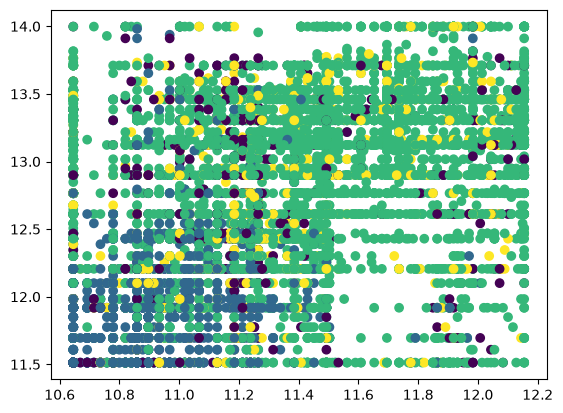

In [282]:
plt.scatter(X['annual_income'], X['coverage_amount'], c = X['km_cluster'])

In [283]:
from sklearn.decomposition import PCA
#principal components analysis

In [289]:
pca = PCA(n_components=2)

X_scaled_pca = pca.fit_transform(X_scaled)
X_scaled_pca

array([[ 2.58782878, -0.78664271],
       [-1.08885234, -1.35198415],
       [-2.40523358,  0.34274149],
       ...,
       [ 0.79549175, -0.55257137],
       [ 0.3880614 ,  0.82202351],
       [ 1.37966742, -1.13708358]], shape=(9930, 2))

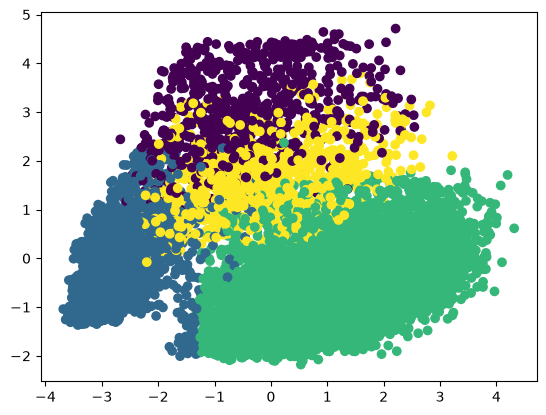

In [ ]:
plt.scatter(X_scaled_pca[:,0], X_scaled_pca[:,1], c=km_cluster)

In [294]:
pca.explained_variance_ratio_

array([0.31284441, 0.12970887])

In [296]:
km.cluster_centers_

centroid_pca = pca.transform(km.cluster_centers_)
centroid_pca

array([[-0.40432509,  3.02336888],
       [-2.70159233, -0.19610591],
       [ 1.22045804, -0.48766931],
       [-0.14382344,  1.58922411]])

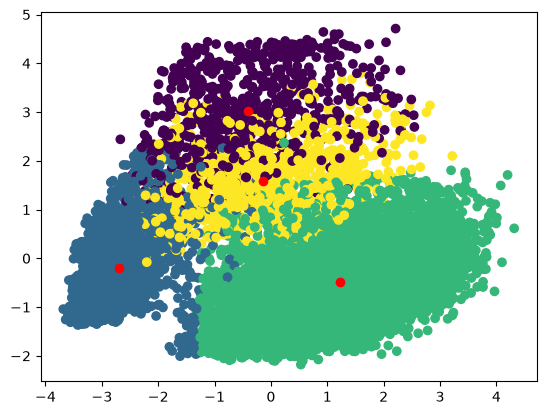

In [297]:
plt.scatter(X_scaled_pca[:,0], X_scaled_pca[:,1], c=km_cluster)
plt.scatter(centroid_pca[:,0], centroid_pca[:,1], c='red')

In [299]:
X

,age,gender,number_of_dependents,annual_income,health_status,coverage_amount,monthly_premium,marital_status_Divorced,marital_status_Married,marital_status_Single,marital_status_Widowed,tenure,km_cluster
0,53,0,3,11.695255,2.0,13.458837,325.9,0.0,1.0,0.0,0.0,4.2,2
1,26,0,1,10.896758,1.0,11.512935,67.4,0.0,1.0,0.0,0.0,4.4,2
2,47,0,0,10.859018,1.0,12.429220,60.7,0.0,0.0,1.0,0.0,4.1,1
3,47,1,0,11.034906,1.0,11.918397,38.1,0.0,0.0,1.0,0.0,3.9,1
4,52,0,3,11.951187,2.0,13.710151,126.3,0.0,1.0,0.0,0.0,3.9,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9925,28,1,0,11.034906,2.0,12.206078,52.7,0.0,0.0,1.0,0.0,4.4,1
9926,33,1,1,11.127278,1.0,12.468441,96.1,0.0,1.0,0.0,0.0,4.2,2
9927,26,0,2,11.440366,0.0,13.122365,78.1,0.0,1.0,0.0,0.0,4.0,2
9928,65,0,2,11.385103,0.0,11.512935,38.1,0.0,1.0,0.0,0.0,3.8,2


In [300]:
X.to_csv('life_insurance_cleaned.csv')

In [301]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
try: print('existing db?', type(db))
except NameError: print('no db var')
_ms=24
_d,_=NearestNeighbors(n_neighbors=_ms).fit(X_scaled).kneighbors(X_scaled)
_kd=np.sort(_d[:,-1])
print('kdist percentiles', {p: round(np.percentile(_kd,p),2) for p in [50,75,90,95,98,99]})
for _eps in [0.5,1.0,1.5,2.0,2.5,3.0]:
    _lab=DBSCAN(eps=_eps,min_samples=_ms).fit_predict(X_scaled)
    _vc=pd.Series(_lab).value_counts()
    _m=_lab!=-1
    _s = round(silhouette_score(X_scaled[_m],_lab[_m]),3) if len(set(_lab[_m]))>1 else '-'
    print(_eps, 'clusters', len(set(_lab))-(1 if -1 in _lab else 0), 'noise', int((_lab==-1).sum()), _vc.head(8).to_dict(), _s)

existing db? <class 'sklearn.cluster._dbscan.DBSCAN'>
kdist percentiles {50: np.float64(1.28), 75: np.float64(1.64), 90: np.float64(2.0), 95: np.float64(2.26), 98: np.float64(2.54), 99: np.float64(2.79)}
0.5 clusters 3 noise 9388 {-1: 9388, 0: 368, 1: 111, 2: 63} 0.302
1.0 clusters 12 noise 5689 {-1: 5689, 3: 768, 7: 741, 2: 733, 5: 484, 0: 466, 4: 355, 1: 310} 0.184
1.5 clusters 11 noise 1489 {0: 2843, 3: 2548, -1: 1489, 1: 1450, 2: 958, 4: 311, 6: 89, 7: 70} 0.201
2.0 clusters 8 noise 184 {0: 3143, 3: 2785, 1: 1470, 2: 987, 5: 441, 4: 335, 6: 323, 7: 262} 0.183
2.5 clusters 4 noise 32 {0: 5943, 1: 2469, 3: 820, 2: 666, -1: 32} 0.335
3.0 clusters 4 noise 3 {0: 5944, 1: 2475, 3: 829, 2: 679, -1: 3} 0.334


In [302]:
print(db)
_l=db.labels_; print(pd.Series(_l).value_counts().head(10).to_dict(), len(set(_l)))

DBSCAN(eps=2.5)
{0: 5943, 1: 2473, 3: 829, 2: 675, -1: 10} 5


In [303]:
_lab4 = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(X_scaled)
_d = df[df['health_status']!='_RARE_'].reset_index(drop=True)
print(len(_d), len(X))
_d = _d.assign(cluster=_lab4)
num = ['age','number_of_dependents','annual_income','coverage_amount','monthly_premium']
prof = _d.groupby('cluster')[num].median()
prof['n'] = _d['cluster'].value_counts()
prof['pct']=(prof['n']/len(_d)*100).round(1)
print(prof.round(1).T)
for c in ['marital_status','gender','health_status','smoking_status','policy_type']:
    print('\n',c); print((pd.crosstab(_d['cluster'],_d[c],normalize='index')*100).round(0))
_d['cov_x_income']=_d['coverage_amount']/_d['annual_income']
_d['prem_pct_income']=_d['monthly_premium']*12/_d['annual_income']*100
print(_d.groupby('cluster')[['cov_x_income','prem_pct_income']].median().round(2))

9964 9930


ValueError: Length of values (9930) does not match length of index (9964)

In [304]:
_x = X.copy()
_x['cluster']=_lab4
_x['income']=np.expm1(_x['annual_income']); _x['coverage']=np.expm1(_x['coverage_amount'])
_x['marital']=_x[[c for c in _x.columns if c.startswith('marital_status_')]].idxmax(axis=1).str.replace('marital_status_','')
g=_x.groupby('cluster')
p=g[['age','number_of_dependents','income','coverage','monthly_premium','health_status','gender','tenure']].median()
p['mean_dep']=g['number_of_dependents'].mean(); p['mean_health']=g['health_status'].mean(); p['male_pct']=g['gender'].mean()*100
p['n']=g.size(); p['pct']=p['n']/len(_x)*100
p['cov_x_inc']=(_x['coverage']/_x['income']).groupby(_x['cluster']).median()
p['prem_pct_inc']=(_x['monthly_premium']*12/_x['income']*100).groupby(_x['cluster']).median()
print(p.round(2).T)
print((pd.crosstab(_x['cluster'],_x['marital'],normalize='index')*100).round(0))
print((pd.crosstab(_x['cluster'],_x['health_status'],normalize='index')*100).round(0))
print(g['age'].describe().round(0))

cluster                       0          1          2          3
age                       53.00      33.00      42.00      46.00
number_of_dependents       1.00       0.00       2.00       1.00
income                 72000.00   54000.00   94000.00   76000.00
coverage              300000.00  150000.00  400000.00  300000.00
monthly_premium           95.60      58.50     135.50     110.10
health_status              1.00       1.00       1.00       1.00
gender                     1.00       0.00       0.00       0.00
tenure                     4.20       4.30       4.30       4.30
mean_dep                   0.86       0.04       1.86       1.26
mean_health                0.86       1.36       1.26       1.13
male_pct                  56.41      39.62      47.37      44.82
n                        679.00    2519.00    5902.00     830.00
pct                        6.84      25.37      59.44       8.36
cov_x_inc                  3.57       2.73       4.17       3.70
prem_pct_inc             

In [305]:
from sklearn.preprocessing import StandardScaler
_f = ['age','number_of_dependents','annual_income','coverage_amount','monthly_premium','health_status']
_X2 = X[_f].copy()
print('premium skew', round(_X2['monthly_premium'].skew(),2), 'log', round(np.log1p(_X2['monthly_premium']).skew(),2))
_X2['monthly_premium']=np.log1p(_X2['monthly_premium'])
_X2s = StandardScaler().fit_transform(_X2)
for _k in range(2,9):
    _m=KMeans(n_clusters=_k,n_init=10,random_state=42).fit(_X2s)
    print(_k, round(_m.inertia_), round(silhouette_score(_X2s,_m.labels_),3), round(calinski_harabasz_score(_X2s,_m.labels_),1))

premium skew 1.74 log 0.42
2 38407 0.309 5473.2
3 33796 0.251 3786.8
4 29792 0.224 3308.3
5 27379 0.196 2918.3
6 25204 0.197 2707.1
7 23591 0.202 2523.1
8 22216 0.205 2384.0


In [277]:
def _prof(k):
    lab=KMeans(n_clusters=k,n_init=10,random_state=42).fit_predict(_X2s)
    t=X[_f].copy(); t['income']=np.expm1(t['annual_income']); t['coverage']=np.expm1(t['coverage_amount'])
    t['c']=lab; t['mar']=_x['marital']
    g=t.groupby('c')
    p=g[['age','income','coverage','monthly_premium']].median()
    p['dep']=g['number_of_dependents'].mean(); p['health']=g['health_status'].mean()
    p['fair%']=g['health_status'].apply(lambda s:(s==0).mean()*100); p['exc%']=g['health_status'].apply(lambda s:(s==2).mean()*100)
    p['cov/inc']=(t['coverage']/t['income']).groupby(t['c']).median()
    p['prem%inc']=(t['monthly_premium']*12/t['income']*100).groupby(t['c']).median()
    p['n']=g.size(); p['pct']=p['n']/len(t)*100
    print(f'--- k={k}'); print(p.round(2).T)
    print((pd.crosstab(t['c'],t['mar'],normalize='index')*100).round(0))
    print('ARI vs marital-based k4:', )
    return lab
for k in [2,3,4]: _prof(k)
from sklearn.metrics import adjusted_rand_score
print('ARI k4 new vs old', adjusted_rand_score(_lab4, KMeans(n_clusters=4,n_init=10,random_state=42).fit_predict(_X2s)))

--- k=2
c                        0          1
age                  36.00      47.00
income            56000.00   98000.00
coverage         150000.00  520000.00
monthly_premium      61.60     210.00
dep                   0.44       2.07
health                1.31       1.19
fair%                14.41      16.33
exc%                 45.64      35.33
cov/inc               2.78       5.05
prem%inc              1.30       2.31
n                  4816.00    5114.00
pct                  48.50      51.50
mar  Divorced  Married  Single  Widowed
c                                      
0         8.0     34.0    51.0      7.0
1         9.0     84.0     1.0      6.0
ARI vs marital-based k4:
--- k=3
c                        0          1          2
age                  54.00      32.00      45.00
income            68000.00   56000.00  102000.00
coverage         250000.00  150000.00  520000.00
monthly_premium      89.30      60.90     216.95
dep                   0.93       0.39       2.18
health     

In [306]:
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

feature2 = ['age','number_of_dependents','annual_income','coverage_amount','monthly_premium','health_status']
_X2 = X[feature2].copy(); _X2['monthly_premium']=np.log1p(_X2['monthly_premium'])
_X2s = StandardScaler().fit_transform(_X2)
_c = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(_X2s)

# plot data in real units
_v = X[feature2].copy()
_v['annual_income']=np.expm1(_v['annual_income']); _v['coverage_amount']=np.expm1(_v['coverage_amount'])
_v['cluster']=_c
# name segments by median age / income
_med=_v.groupby('cluster')[['age','annual_income']].median()
_names={_med['age'].idxmin():'Young & Healthy Starters', _med['annual_income'].idxmax():'Affluent Family Protectors'}
_names[[k for k in range(3) if k not in _names][0]]='Older, Health-Risk'
_v['segment']=_v['cluster'].map(_names)
order=['Young & Healthy Starters','Affluent Family Protectors','Older, Health-Risk']
pal=dict(zip(order,['#2a78d6','#eb6834','#1baf7a']))
print(_names, _v['segment'].value_counts().to_dict())

sns.set_theme(style='whitegrid', rc={'axes.edgecolor':'#c3c2b7','grid.color':'#e8e7e3','axes.labelcolor':'#52514e','xtick.color':'#52514e','ytick.color':'#52514e','axes.titleweight':'bold','axes.titlesize':12})
SP=r'C:\Users\arifw\AppData\Local\Temp\claude\C--Users-arifw-Documents-Personal-Documents-Jasaraharja-Putera-IT-General-Pelatihan-Machine-Learning\a93662c1-cbc8-47e3-a0bb-78db1ecb5049\scratchpad'

# 1. PCA
_pca=PCA(n_components=2, random_state=42); _pc=_pca.fit_transform(_X2s)
fig,ax=plt.subplots(figsize=(9,6))
sns.scatterplot(x=_pc[:,0],y=_pc[:,1],hue=_v['segment'],hue_order=order,palette=pal,s=10,alpha=0.35,linewidth=0,ax=ax)
ev=_pca.explained_variance_ratio_*100
ax.set(xlabel=f'PC1 ({ev[0]:.0f}% of variance)', ylabel=f'PC2 ({ev[1]:.0f}% of variance)', title='Customer segments projected to 2D (PCA)')
ax.legend(title=None, markerscale=2.5, frameon=False)
fig.tight_layout(); fig.savefig(SP+r'\v1.png',dpi=90); plt.close(fig)

# 2. income vs coverage
fig,ax=plt.subplots(figsize=(9,6))
sns.scatterplot(data=_v.sample(frac=1,random_state=1),x='annual_income',y='coverage_amount',hue='segment',hue_order=order,palette=pal,s=12,alpha=0.35,linewidth=0,ax=ax)
ax.set(xscale='log',yscale='log',xlabel='Annual income (log scale)',ylabel='Coverage amount (log scale)',title='Income vs coverage by segment')
from matplotlib.ticker import FuncFormatter
fmt=FuncFormatter(lambda x,_: f'{x/1000:.0f}k'); ax.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(fmt); 
ax.legend(title=None, markerscale=2.5, frameon=False)
fig.tight_layout(); fig.savefig(SP+r'\v2.png',dpi=90); plt.close(fig)

# 3. profiles
cols=[('age','Age'),('number_of_dependents','Dependents'),('annual_income','Annual income'),('coverage_amount','Coverage amount'),('monthly_premium','Monthly premium')]
fig,axes=plt.subplots(1,5,figsize=(18,4.5))
for a,(c,t) in zip(axes,cols):
    sns.boxplot(data=_v,x='segment',y=c,hue='segment',order=order,hue_order=order,palette=pal,showfliers=False,width=0.6,linewidth=1,ax=a,legend=False)
    a.set(title=t,xlabel='',ylabel=''); a.set_xticks(range(3)); a.set_xticklabels(['Young','Affluent','Older'])
    if c in ('annual_income','coverage_amount'): a.yaxis.set_major_formatter(fmt)
fig.suptitle('What each segment looks like', fontweight='bold'); fig.tight_layout(); fig.savefig(SP+r'\v3.png',dpi=80); plt.close(fig)

# 4. health 100% bars
_h=(pd.crosstab(_v['segment'],_v['health_status'],normalize='index')*100).reindex(order).rename(columns={0.0:'Fair',1.0:'Good',2.0:'Excellent'})
fig,ax=plt.subplots(figsize=(9,3.8))
hc={'Fair':'#e34948','Good':'#c3c2b7','Excellent':'#2a78d6'}
left=np.zeros(3)
for k in ['Fair','Good','Excellent']:
    ax.barh(order,_h[k],left=left,color=hc[k],edgecolor='white',linewidth=2,label=k)
    for i,(l,w) in enumerate(zip(left,_h[k])):
        ax.text(l+w/2,i,f'{w:.0f}%',ha='center',va='center',color='white' if k!='Good' else '#0b0b0b',fontsize=10)
    left+=_h[k].values
ax.invert_yaxis(); ax.set(xlim=(0,100),xlabel='% of customers in segment',title='Health status by segment'); ax.grid(False)
ax.legend(ncol=3,loc='lower center',bbox_to_anchor=(0.5,1.08),frameon=False)
fig.tight_layout(); fig.savefig(SP+r'\v4.png',dpi=90); plt.close(fig)
print(ev)

{np.int32(1): 'Young & Healthy Starters', np.int32(2): 'Affluent Family Protectors', 0: 'Older, Health-Risk'} {'Affluent Family Protectors': 4322, 'Young & Healthy Starters': 3609, 'Older, Health-Risk': 1999}
[47.6246577  18.54853746]


In [307]:
fig,ax=plt.subplots(figsize=(9,3.6))
hc={'Fair':'#9ec5f4','Good':'#3987e5','Excellent':'#104281'}
left=np.zeros(3)
for k in ['Fair','Good','Excellent']:
    ax.barh(order,_h[k],left=left,color=hc[k],edgecolor='white',linewidth=2,label=k)
    for i,(l,w) in enumerate(zip(left,_h[k])):
        ax.text(l+w/2,i,f'{w:.0f}%',ha='center',va='center',color='#0b0b0b' if k=='Fair' else 'white',fontsize=10)
    left+=_h[k].values
ax.invert_yaxis(); ax.set(xlim=(0,100),xlabel='% of customers in segment'); ax.grid(False)
ax.set_title('Health status by segment', loc='left', pad=28)
ax.legend(ncol=3,loc='lower left',bbox_to_anchor=(0,1.0),frameon=False)
fig.tight_layout(); fig.savefig(SP+r'\v4.png',dpi=90); plt.close(fig)